# HAM10000 - lesion-level split, CNN baseline, EfficientNetB0, Grad-CAM
Run in Google Colab with a T4 GPU (Runtime > Change runtime type).
Set FAST_MODE = True for a quick smoke test, False for the final run.
Research demonstration only; not for clinical use.



In [1]:
import json
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, f1_score, balanced_accuracy_score,
                             roc_auc_score, ConfusionMatrixDisplay)
from tensorflow.keras import layers, models

FAST_MODE = False                      # True = quick pipeline check, False = final run
SEED = 42
BATCH = 32
if FAST_MODE:
    IMG_SIZE, CNN_EPOCHS, HEAD_EPOCHS, FINETUNE_EPOCHS, N_BOOT = 128, 8, 5, 5, 200
    RESULTS_NAME = "HAM10000_results_fast"
else:
    IMG_SIZE, CNN_EPOCHS, HEAD_EPOCHS, FINETUNE_EPOCHS, N_BOOT = 224, 30, 10, 15, 1000
    RESULTS_NAME = "HAM10000_results_final"
AUTOTUNE = tf.data.AUTOTUNE
tf.keras.utils.set_random_seed(SEED)

print("TensorFlow:", tf.__version__)
gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU. Runtime > Change runtime type > T4 GPU, then rerun from the top.")



TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive")
IMG_DIR = Path("/content/skin_cancer_images")
RESULTS_DIR = DATA_DIR / RESULTS_NAME
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
IMG_DIR.mkdir(parents=True, exist_ok=True)

for fname in ["HAM10000_metadata.csv", "HAM10000_images_part_1.zip", "HAM10000_images_part_2.zip"]:
    if not (DATA_DIR / fname).is_file():
        raise FileNotFoundError(f"Missing file in MyDrive: {fname}")

df = pd.read_csv(DATA_DIR / "HAM10000_metadata.csv")
expected_ids = set(df["image_id"].astype(str))


def image_map():
    return {p.stem: str(p) for p in IMG_DIR.rglob("*.jpg")}


paths = image_map()
if not expected_ids.issubset(paths.keys()):
    for name in ["HAM10000_images_part_1.zip", "HAM10000_images_part_2.zip"]:
        print("Extracting:", name)
        with zipfile.ZipFile(DATA_DIR / name) as archive:
            archive.extractall(IMG_DIR)
    paths = image_map()

missing = expected_ids - set(paths)
if missing:
    raise RuntimeError(f"{len(missing)} images missing, e.g. {list(missing)[:5]}")
df["path"] = df["image_id"].map(paths)
class_names = sorted(df["dx"].unique().tolist())
df["label"] = pd.Categorical(df["dx"], categories=class_names).codes.astype("int32")
NUM_CLASSES = len(class_names)
MEL = class_names.index("mel")
assert NUM_CLASSES == 7
print(f"Images: {len(df)} | unique lesions: {df.lesion_id.nunique()}")
print(df["dx"].value_counts())



Mounted at /content/drive
Extracting: HAM10000_images_part_1.zip
Extracting: HAM10000_images_part_2.zip
Images: 10015 | unique lesions: 7470
dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64


In [3]:
test_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
trainval_idx, test_idx = next(test_split.split(df, df.label, groups=df.lesion_id))
trainval, test = df.iloc[trainval_idx].copy(), df.iloc[test_idx].copy()
val_split = StratifiedGroupKFold(n_splits=8, shuffle=True, random_state=SEED)
train_idx, val_idx = next(val_split.split(trainval, trainval.label, groups=trainval.lesion_id))
train, val = trainval.iloc[train_idx].copy(), trainval.iloc[val_idx].copy()

parts = {"train": train, "val": val, "test": test}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(parts[a].lesion_id).isdisjoint(set(parts[b].lesion_id)), "Lesion leakage!"
for name, part in parts.items():
    assert set(part.label) == set(range(NUM_CLASSES)), f"Missing class in {name}; change SEED"
    print(name, len(part), "images,", part.lesion_id.nunique(), "lesions")
print(pd.DataFrame({n: p.dx.value_counts() for n, p in parts.items()}).fillna(0).astype(int))
for name, part in parts.items():
    part[["image_id", "lesion_id", "dx", "label"]].to_csv(RESULTS_DIR / f"{name}_split.csv", index=False)



train 6981 images, 5229 lesions
val 1020 images, 746 lesions
test 2014 images, 1495 lesions
       train  val  test
dx                     
akiec    239   20    68
bcc      358   56   100
bkl      777  117   205
df        79   14    22
mel      758  133   222
nv      4676  666  1363
vasc      94   14    34


In [4]:
weights = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=train.label.to_numpy())
class_weight = dict(enumerate(weights.astype(float)))
print("Class weights:", {class_names[i]: round(w, 2) for i, w in class_weight.items()})


def load_image(path, label):
    image = tf.io.decode_jpeg(tf.io.read_file(path), channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))        # float32, 0-255
    return image, tf.cast(label, tf.int32)


def make_dataset(frame, training=False):
    p = frame.path.astype(str).to_numpy()
    assert all(x.startswith("/content/skin_cancer_images/") for x in p), "Images must be on local disk"
    ds = tf.data.Dataset.from_tensor_slices((p, frame.label.to_numpy(dtype=np.int32)))
    if training:
        ds = ds.shuffle(len(frame), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)


train_ds, val_ds, test_ds = make_dataset(train, True), make_dataset(val), make_dataset(test)
xb, yb = next(iter(train_ds.take(1)))
print("Batch:", xb.shape, xb.dtype)
print("Pixel min/max/mean:", float(tf.reduce_min(xb)), float(tf.reduce_max(xb)), float(tf.reduce_mean(xb)))
print("Labels in first batch:", np.bincount(yb.numpy(), minlength=NUM_CLASSES))




Class weights: {'akiec': np.float64(4.17), 'bcc': np.float64(2.79), 'bkl': np.float64(1.28), 'df': np.float64(12.62), 'mel': np.float64(1.32), 'nv': np.float64(0.21), 'vasc': np.float64(10.61)}
Batch: (32, 224, 224, 3) <dtype: 'float32'>
Pixel min/max/mean: 0.0 255.0 164.51829528808594
Labels in first batch: [ 1  2  4  0  5 18  2]


In [5]:
def callbacks(name, patience=6):
    return [
        tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6),
        tf.keras.callbacks.CSVLogger(str(RESULTS_DIR / f"{name}_training.csv")),
    ]


def plot_history(histories, name):
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    for phase, h in enumerate(histories, 1):
        ax[0].plot(h.history["loss"], label=f"train phase {phase}")
        ax[1].plot(h.history["val_loss"], label=f"val phase {phase}")
    ax[0].set_title("Training loss"); ax[1].set_title("Validation loss")
    for a in ax:
        a.set_xlabel("Epoch within phase"); a.legend()
    plt.tight_layout(); fig.savefig(RESULTS_DIR / f"{name}_history.png", dpi=180); plt.show()


def predict_probs(model, ds):
    prob = model.predict(ds, verbose=0)
    return prob / prob.sum(axis=1, keepdims=True)       # guard: rows sum exactly to 1


def cluster_bootstrap_ci(frame, pred, n_boot=N_BOOT, seed=SEED):
    """95% CI by resampling LESIONS (images of one lesion are correlated)."""
    true = frame.label.to_numpy(int)
    groups = list(frame.reset_index(drop=True).groupby("lesion_id").indices.values())
    rng = np.random.default_rng(seed)
    out = {"macro_f1": [], "balanced_accuracy": [], "melanoma_recall": []}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for _ in range(n_boot):
            pick = rng.integers(0, len(groups), len(groups))
            idx = np.concatenate([groups[i] for i in pick])
            t, p = true[idx], pred[idx]
            out["macro_f1"].append(f1_score(t, p, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0))
            out["balanced_accuracy"].append(balanced_accuracy_score(t, p))
            m = t == MEL
            out["melanoma_recall"].append(np.mean(p[m] == MEL) if m.any() else np.nan)
    return {k: np.nanpercentile(v, [2.5, 97.5]) for k, v in out.items()}


def evaluate_model(model, ds, frame, name, split="validation", with_ci=False, make_plot=False):
    true = frame.label.to_numpy(dtype=int)
    prob = predict_probs(model, ds)
    pred = prob.argmax(axis=1)
    print(f"\n{name} - {split}")
    print(classification_report(true, pred, labels=np.arange(NUM_CLASSES),
                                target_names=class_names, digits=3, zero_division=0))
    res = dict(model=name, split=split,
               accuracy=float(np.mean(true == pred)),
               macro_f1=float(f1_score(true, pred, labels=np.arange(NUM_CLASSES), average="macro", zero_division=0)),
               balanced_accuracy=float(balanced_accuracy_score(true, pred)),
               melanoma_recall=float(np.mean(pred[true == MEL] == MEL)))
    try:
        res["macro_auc_ovr"] = float(roc_auc_score(true, prob, labels=np.arange(NUM_CLASSES),
                                                   multi_class="ovr", average="macro"))
    except ValueError as err:
        print("AUC could not be computed:", err)      # not silent
        res["macro_auc_ovr"] = np.nan
    if with_ci:
        for k, (lo, hi) in cluster_bootstrap_ci(frame, pred).items():
            res[f"{k}_ci_low"], res[f"{k}_ci_high"] = float(lo), float(hi)
    if make_plot:
        ConfusionMatrixDisplay.from_predictions(true, pred, labels=np.arange(NUM_CLASSES),
                                                display_labels=class_names, normalize="true",
                                                cmap="Blues", xticks_rotation=45, values_format=".2f")
        plt.title(f"{name} - {split} (row-normalized)"); plt.tight_layout()
        plt.savefig(RESULTS_DIR / f"{name}_{split}_confusion_matrix.png", dpi=180); plt.show()
    return res


def val_macro_f1(model):
    pred = predict_probs(model, val_ds).argmax(axis=1)
    return f1_score(val.label.to_numpy(int), pred, labels=np.arange(NUM_CLASSES),
                    average="macro", zero_division=0)




Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 307ms/step - accuracy: 0.3782 - loss: 1.7569 - val_accuracy: 0.2824 - val_loss: 1.7915 - learning_rate: 0.0010
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 76s 332ms/step - accuracy: 0.4137 - loss: 1.6650 - val_accuracy: 0.4951 - val_loss: 1.2251 - learning_rate: 0.0010
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 73s 332ms/step - accuracy: 0.4234 - loss: 1.5281 - val_accuracy: 0.4500 - val_loss: 1.3863 - learning_rate: 0.0010
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 69s 314ms/step - accuracy: 0.4257 - loss: 1.4910 - val_accuracy: 0.1333 - val_loss: 3.6817 - learning_rate: 0.0010
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 66s 302ms/step - accuracy: 0.4515 - loss: 1.4344 - val_accuracy: 0.4392 - val_loss: 1.4379 - learning_rate: 0.0010
Epoch 6/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 83s 307ms/step - accuracy: 0.4663 - loss: 1.3566 - val_accuracy: 0.4353 - val_loss: 1.4583 - learning_rate: 5.0000e-04
Epoch 7/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 68s 309ms/step - accuracy:

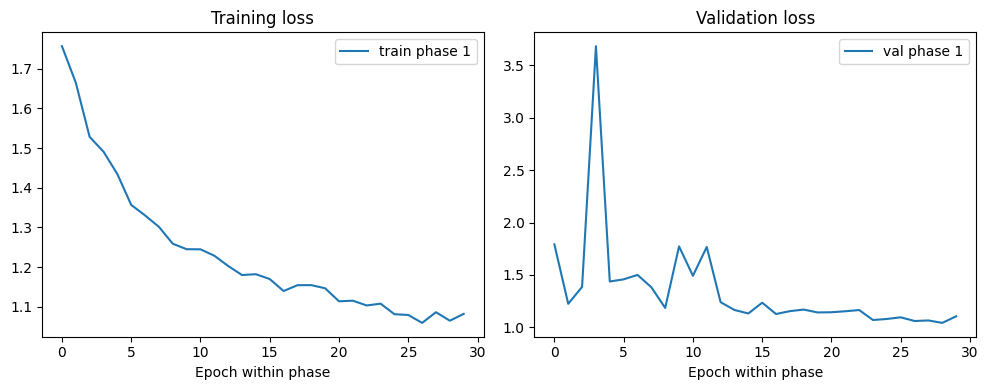

In [6]:
def conv_bn(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", use_bias=False, kernel_initializer="he_normal")(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)


def build_cnn():
    # BatchNorm + He init: a plain ReLU CNN without them can get stuck at chance level
    # (loss = ln(7) = 1.946) when trained from scratch with class weights.
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.RandomFlip("horizontal_and_vertical")(inp)
    x = layers.RandomRotation(0.1)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64, 128, 128):
        x = conv_bn(x, filters)
        x = conv_bn(x, filters)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.3)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    m = models.Model(inp, out, name="baseline_cnn")
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m


cnn = build_cnn()
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=CNN_EPOCHS,
                class_weight=class_weight, callbacks=callbacks("cnn", 8), verbose=1)
plot_history([h_cnn], "cnn")
cnn.save(RESULTS_DIR / "baseline_cnn.keras")



16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 58s 194ms/step - accuracy: 0.4085 - loss: 1.6273 - val_accuracy: 0.5784 - val_loss: 1.1632 - learning_rate: 0.0010
Epoch 2/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 45s 205ms/step - accuracy: 0.5224 - loss: 1.3175 - val_accuracy: 0.5627 - val_loss: 1.1990 - learning_rate: 0.0010
Epoch 3/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 41s 185ms/step - accuracy: 0.5612 - loss: 1.2021 - val_accuracy: 0.6275 - val_loss: 1.0679 - learning_rate: 0.0010
Epoch 4/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 46s 208ms/step - accuracy: 0.5809 - loss: 1.1350 - val_accuracy: 0.6196 - val_loss: 1.0491 - learning_rate: 0.0010
Epoch 5/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 41s 187ms/step - accuracy: 0.5966 - loss: 1.0871 - val_accuracy: 0.6500 - val_loss: 0.9677 - learning_rate: 0.0010
Epoch 6/10
219/219 ━━━━━━━━━━━━━━━━━━━━ 39s 179ms/step - accuracy: 0.5969 - loss: 1.0624 - val_accuracy: 0.6402 - val_loss: 1.0018 - learning_rate: 0.0010
Epoch 7/10
219/219 

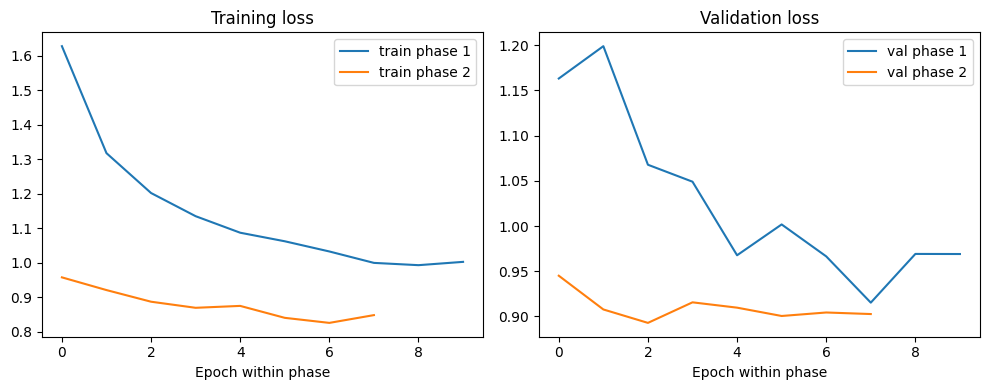

In [7]:
# EfficientNet in Keras has preprocessing built in and expects pixels in [0, 255].
inputs = layers.Input((IMG_SIZE, IMG_SIZE, 3))
x = layers.RandomFlip("horizontal_and_vertical")(inputs)
x = layers.RandomRotation(0.1)(x)
x = layers.RandomZoom(0.1)(x)
base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                            input_shape=(IMG_SIZE, IMG_SIZE, 3))
base.trainable = False
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="head_dropout")(x)
logits = layers.Dense(NUM_CLASSES, name="class_logits")(x)
outputs = layers.Activation("softmax", name="class_probabilities")(logits)
eff = models.Model(inputs, outputs, name="efficientnetb0_skin_lesions")

# Phase 1: train the new head only
eff.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_head = eff.fit(train_ds, validation_data=val_ds, epochs=HEAD_EPOCHS,
                 class_weight=class_weight, callbacks=callbacks("eff_head", 4), verbose=1)
head_weights = eff.get_weights()
head_f1 = val_macro_f1(eff)

# Phase 2: fine-tune the top layers (BatchNorm stays frozen)
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
eff.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h_fine = eff.fit(train_ds, validation_data=val_ds, epochs=FINETUNE_EPOCHS,
                 class_weight=class_weight, callbacks=callbacks("eff_fine", 5), verbose=1)
fine_f1 = val_macro_f1(eff)
print(f"Validation macro-F1 | head only: {head_f1:.3f} | after fine-tuning: {fine_f1:.3f}")
if head_f1 > fine_f1:
    eff.set_weights(head_weights)
    print("Restored head-only weights (better validation macro-F1).")
plot_history([h_head, h_fine], "effnet")
eff.save(RESULTS_DIR / "efficientnetb0.keras")




CNN - validation
              precision    recall  f1-score   support

       akiec      0.191     0.450     0.269        20
         bcc      0.397     0.554     0.463        56
         bkl      0.353     0.419     0.383       117
          df      0.055     0.286     0.092        14
         mel      0.382     0.549     0.451       133
          nv      0.938     0.640     0.761       666
        vasc      0.316     0.857     0.462        14

    accuracy                          0.592      1020
   macro avg      0.376     0.536     0.411      1020
weighted avg      0.734     0.592     0.638      1020


EfficientNetB0 - validation
              precision    recall  f1-score   support

       akiec      0.643     0.450     0.529        20
         bcc      0.568     0.446     0.500        56
         bkl      0.420     0.650     0.510       117
          df      0.800     0.571     0.667        14
         mel      0.310     0.541     0.395       133
          nv      0.920     0.7

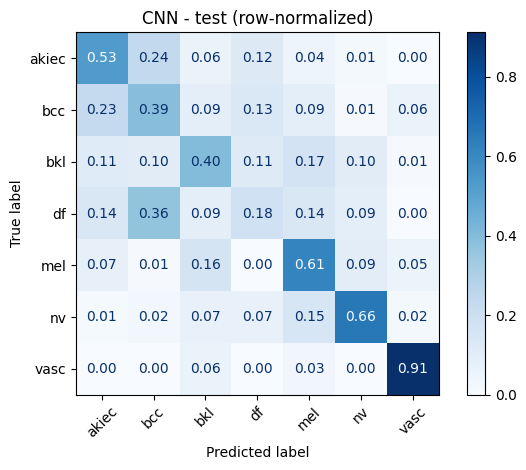


EfficientNetB0 - test
              precision    recall  f1-score   support

       akiec      0.526     0.441     0.480        68
         bcc      0.523     0.450     0.484       100
         bkl      0.395     0.580     0.470       205
          df      0.133     0.182     0.154        22
         mel      0.303     0.613     0.405       222
          nv      0.951     0.717     0.818      1363
        vasc      0.422     0.794     0.551        34

    accuracy                          0.664      2014
   macro avg      0.465     0.540     0.480      2014
weighted avg      0.770     0.664     0.697      2014



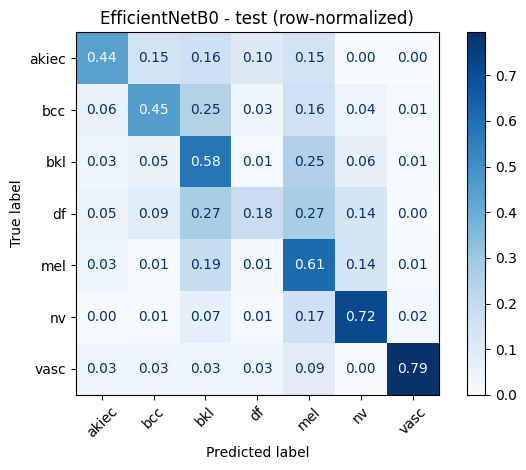

                               0               1
model                        CNN  EfficientNetB0
split                       test            test
accuracy                   0.607           0.664
macro_f1                   0.422            0.48
balanced_accuracy          0.526            0.54
melanoma_recall            0.613           0.613
macro_auc_ovr              0.879           0.902
macro_f1_ci_low            0.385           0.438
macro_f1_ci_high           0.458           0.515
balanced_accuracy_ci_low   0.484           0.494
balanced_accuracy_ci_high  0.574           0.586
melanoma_recall_ci_low     0.524           0.537
melanoma_recall_ci_high    0.692           0.693


In [8]:
val_results = [evaluate_model(cnn, val_ds, val, "CNN", "validation"),
               evaluate_model(eff, val_ds, val, "EfficientNetB0", "validation")]
val_table = pd.DataFrame(val_results)
val_table.to_csv(RESULTS_DIR / "validation_metrics.csv", index=False)
selected_model = val_table.sort_values("macro_f1", ascending=False).iloc[0]["model"]
print("Selected by validation macro-F1:", selected_model)

# Both models are reported on test as a declared comparison; the selected one is the primary result.
test_results = [evaluate_model(cnn, test_ds, test, "CNN", "test", with_ci=True, make_plot=True),
                evaluate_model(eff, test_ds, test, "EfficientNetB0", "test", with_ci=True, make_plot=True)]
test_table = pd.DataFrame(test_results)
test_table.to_csv(RESULTS_DIR / "test_metrics.csv", index=False)
print(test_table.round(3).T)
_ = (RESULTS_DIR / "model_selection.json").write_text(json.dumps({
    "criterion": "validation macro-F1", "selected_model": selected_model, "seed": SEED,
    "img_size": IMG_SIZE, "epochs": {"cnn": CNN_EPOCHS, "head": HEAD_EPOCHS, "finetune": FINETUNE_EPOCHS},
    "class_names": class_names, "ci": f"95% lesion-level bootstrap, {N_BOOT} resamples"}, indent=2))



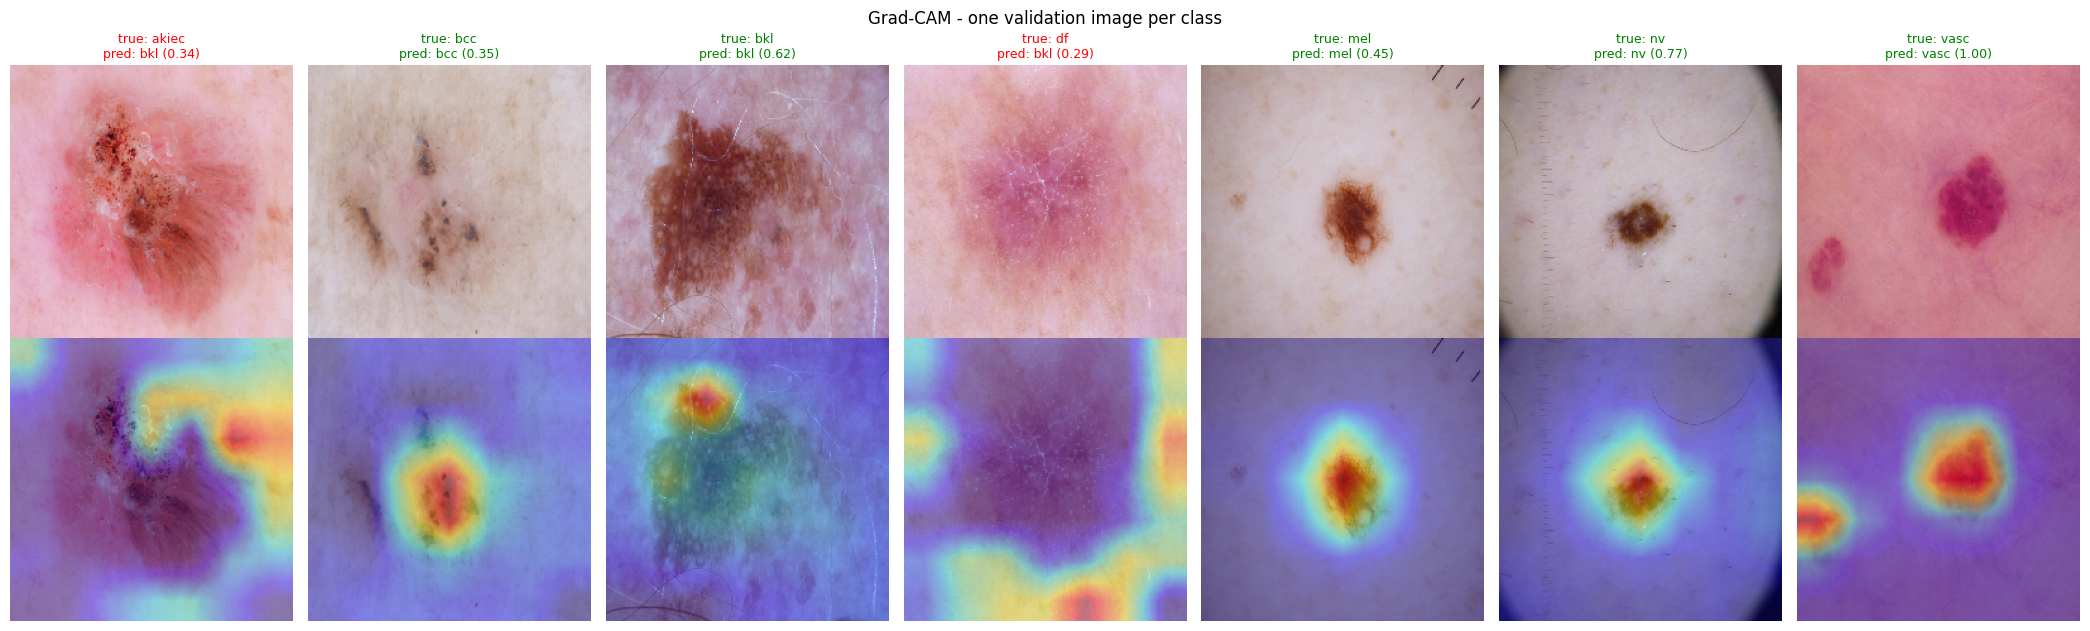

Missed melanomas in validation: 61


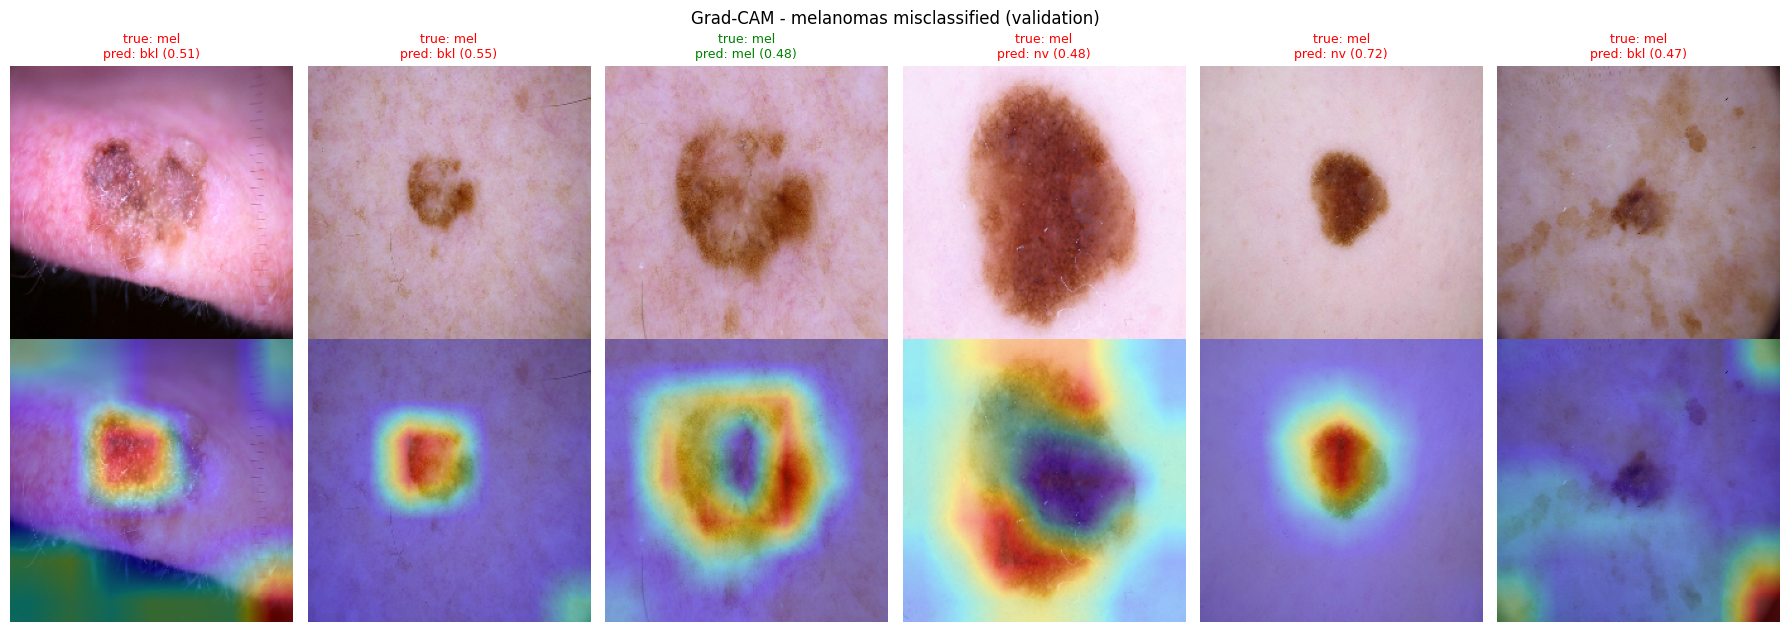

Results saved to: /content/drive/MyDrive/HAM10000_results_final


In [9]:
feature_extractor = tf.keras.Model(base.input, [base.get_layer("top_activation").output, base.output])
gap, head_drop, head_dense = eff.get_layer("gap"), eff.get_layer("head_dropout"), eff.get_layer("class_logits")


def gradcam_heatmap(img):
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_maps, final_maps = feature_extractor(x, training=False)
        z = head_dense(head_drop(gap(final_maps), training=False))
        probs = tf.nn.softmax(z, axis=-1)
        cls = int(tf.argmax(probs[0]).numpy())
        score = z[:, cls]                       # logit of the predicted class
    grads = tape.gradient(score, conv_maps)
    if grads is None:
        raise RuntimeError("Grad-CAM gradients are None; check layer names / Keras version.")
    w = tf.reduce_mean(grads, axis=(1, 2))
    heat = tf.maximum(tf.reduce_sum(conv_maps * w[:, None, None, :], axis=-1)[0], 0)
    heat = heat / (tf.reduce_max(heat) + 1e-8)
    return heat.numpy(), cls, float(probs[0, cls].numpy())


def show_gradcam(rows, fname, title):
    n = len(rows)
    fig, ax = plt.subplots(2, n, figsize=(3 * n, 6.4), squeeze=False)
    for j, (_, rec) in enumerate(rows.iterrows()):
        img = np.asarray(tf.keras.utils.load_img(rec.path, target_size=(IMG_SIZE, IMG_SIZE)), dtype="float32")
        heat, pred, conf = gradcam_heatmap(img)
        up = tf.image.resize(heat[..., None], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
        ax[0, j].imshow(img.astype("uint8"))
        ax[0, j].set_title(f"true: {rec.dx}\npred: {class_names[pred]} ({conf:.2f})", fontsize=9,
                           color="green" if class_names[pred] == rec.dx else "red")
        ax[1, j].imshow(img.astype("uint8")); ax[1, j].imshow(up, alpha=0.4, cmap="jet", vmin=0, vmax=1)
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(title); plt.tight_layout()
    fig.savefig(RESULTS_DIR / fname, dpi=180); plt.show()


# (a) one validation example per class
per_class = val.groupby("label", group_keys=False).sample(1, random_state=SEED)
show_gradcam(per_class, "gradcam_validation_per_class.png", "Grad-CAM - one validation image per class")

# (b) validation melanomas the model missed (most clinically important errors)
val_pred = predict_probs(eff, val_ds).argmax(axis=1)
missed = val[(val.label.to_numpy() == MEL) & (val_pred != MEL)]
print("Missed melanomas in validation:", len(missed))
if len(missed):
    show_gradcam(missed.head(6), "gradcam_validation_missed_melanoma.png",
                 "Grad-CAM - melanomas misclassified (validation)")
print("Results saved to:", RESULTS_DIR)
